# Отчет по практической работе: «Обучение и развертывание моделей классификации изображений»

Цель работы: изучить принципы создания и обучения моделей компьютерного зрения без написания кода в сервисах Google Teachable Machine и Pocket AutoML, интегрировать обученные модели в Python, а также разработать программный интерфейс (API) и клиентское графическое приложение для распознавания изображений.

Задание 1. Классификация изображений «Хот-дог / Не хот-дог»

1. Подготовка данных и обучение модели
В веб-сервисе Teachable Machine был создан стандартный проект с изображениями и два класса: «Хот-дог» и «Не хот-дог». В каждый класс загружено по 249 размеченных изображений из обучающих выборок hot_dog_train и not_hot_dog_train.

Обучение проводилось со следующими параметрами:   Количество эпох: 50.   Размер пакета: 16.   Скорость обучения: 0.001. 

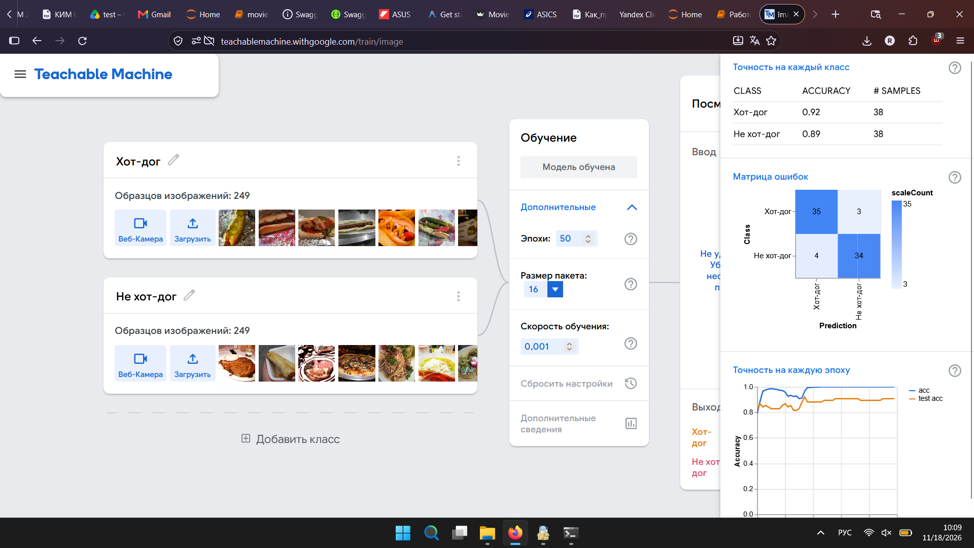

| Класс | Точность (Accuracy) | Количество образцов (# Samples) | Верно распознано | Ошибки |
| :--- | :---: | :---: | :---: | :--- |
| Хот-дог | 0.92 | 38 | 35 | 3 (определены как «Не хот-дог») |
| Не хот-дог | 0.89 | 38 | 34 | 4 (определены как «Хот-дог») |

Суммарно модель правильно классифицировала 69 из 76 проверочных изображений (около 90,8%). По графику точности на каждую эпоху видно, что обучающая выборка быстро выходит к 1.0, а тестовая стабилизируется в районе 0.90, что говорит о хорошем качестве обобщения без критического переобучения

3. Тестирование модели в интерфейсе Teachable Machine
В разделе «Посмотреть» была проведена проверка на изображениях из валидационных папок hot_dog_validation и not_hot_dog_validation.

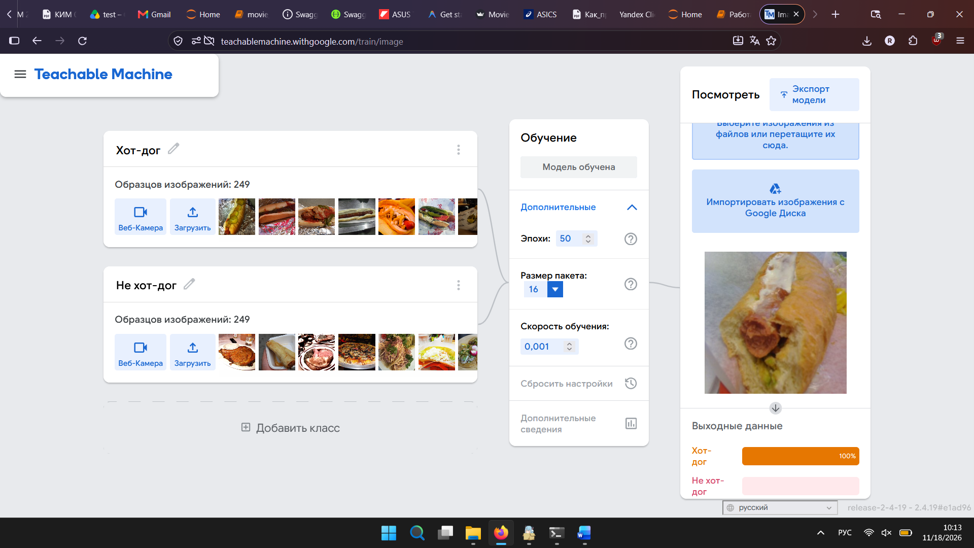

На фотографиях из папки hot_dog_validation модель уверенно выделяет характерные признаки (булочка, сосиска, соус) — на тестовом примере показана уверенность 100% для класса «Хот-дог».

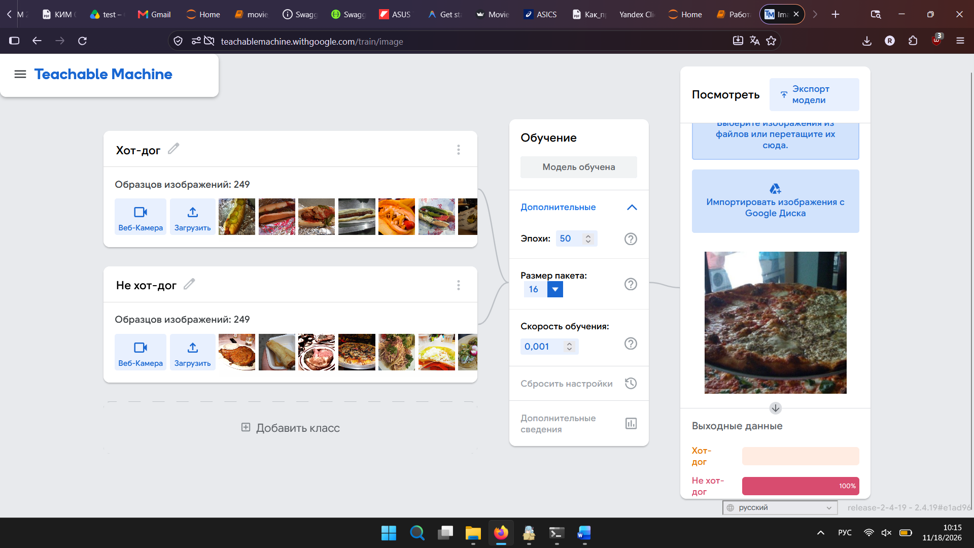

На фотографиях других блюд из папки not_hot_dog_validation (например, пицца) модель корректно относит объект к классу «Не хот-дог» с уверенностью 100%. Ошибки возможны в основном на визуально похожей еде (сэндвичи, шаурма, багеты с начинкой) или при плохом ракурсе.

4. Экспорт и проверка модели в Jupyter Notebook
Обученная модель была экспортирована в формате Keras (keras_Model.h5 и labels.txt) и загружена в Jupyter Notebook.

1/1 [==============================] - 2s 2s/step
------------------------------
Файл: 200438.jpg
Класс: Хот-дог
Уверенность: 1.0000
------------------------------


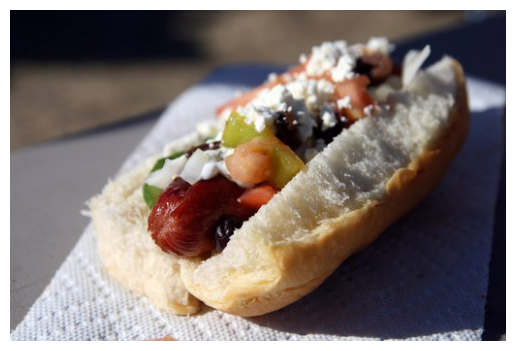

In [20]:
import os
import tf_keras 
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True)

model_path = "keras_Model.h5"
labels_path = "labels.txt"

if not os.path.exists(model_path):
    raise FileNotFoundError(f"Файл модели '{model_path}' не найден! Положи его рядом с ноутбуком.")
if not os.path.exists(labels_path):
    raise FileNotFoundError(f"Файл лейблов '{labels_path}' не найден! Положи его рядом с ноутбуком.")

model = tf_keras.models.load_model(model_path, compile=False)

with open(labels_path, "r", encoding="utf-8") as f:
    class_names = f.readlines()

image_folder = "C:/Users/rafael/Downloads/hot_dog_validation-20240303T060924Z-001/hot_dog_validation"
image_filename = "200438.jpg" 

image_path = os.path.join(image_folder, image_filename)

if not os.path.exists(image_path):
    raise FileNotFoundError(f"Картинка '{image_path}' не найдена! Проверь путь к папке и имя файла.")

data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

image = Image.open(image_path).convert("RGB")
size = (224, 224)
image_resized = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image_resized)

normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index].strip()
confidence_score = prediction[0][index]

print("-" * 30)
print(f"Файл: {image_filename}")
print(f"Класс: {class_name[2:]}") 
print(f"Уверенность: {confidence_score:.4f}")
print("-" * 30)

plt.imshow(image)
plt.axis('off')
plt.show()

Результат теста в Jupyter Notebook:Файл: 200438.jpg.   Предсказанный класс: Хот-дог.   Уверенность: 1.0000 (100%).

Задание 2. Обучение модели на собственной коллекции изображений

1. Сбор данных и обучение модели
Для второго задания была собрана собственная коллекция изображений канцелярских товаров, разделенная на три класса:
Карандаши — 20 изображений.
Ручки — 19 изображений.
Ластики — 20 изображений.   Параметры обучения оставлены стандартными: 50 эпох, размер пакета 16, скорость обучения 0.001.

2. Метрики и анализ ошибок
На внутреннюю проверку Teachable Machine выделил по 3 изображения из каждого класса:

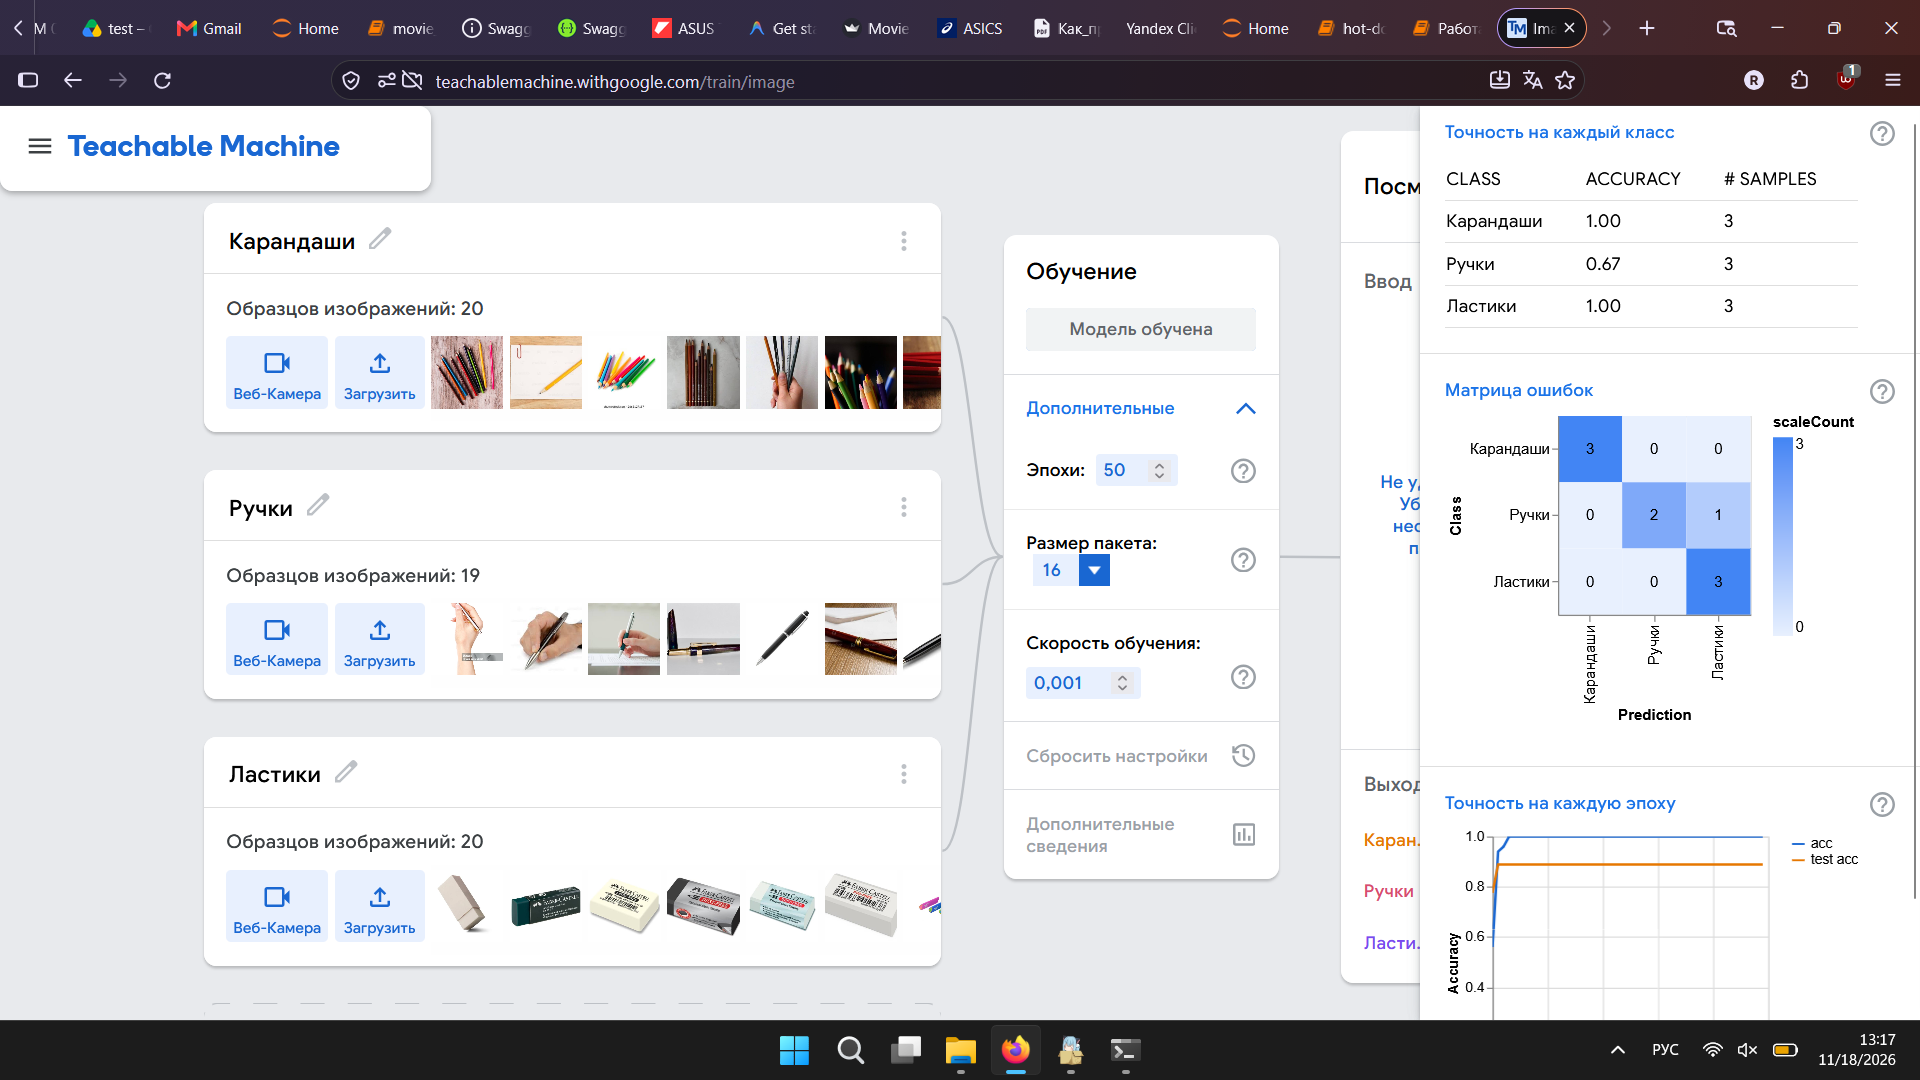

| Класс | Точность (Accuracy) | Количество образцов (# Samples) | Результат по матрице ошибок |
| :--- | :---: | :---: | :--- |
| Карандаши | 1.00 | 3 | 3 из 3 верно |
| Ручки | 0.67 | 3 | 2 верно, 1 ошибочно принята за «Ластики» |
| Ластики | 1.00 | 3 | 3 из 3 верно |

Снижение точности класса «Ручки» до 0.67 объясняется малым размером тестовой выборки (всего 3 образца: одна ошибка сразу снижает метрику на 33%) и разнородным фоном на загруженных фотографиях ручек (часть фото сделана в руках, часть на столе).

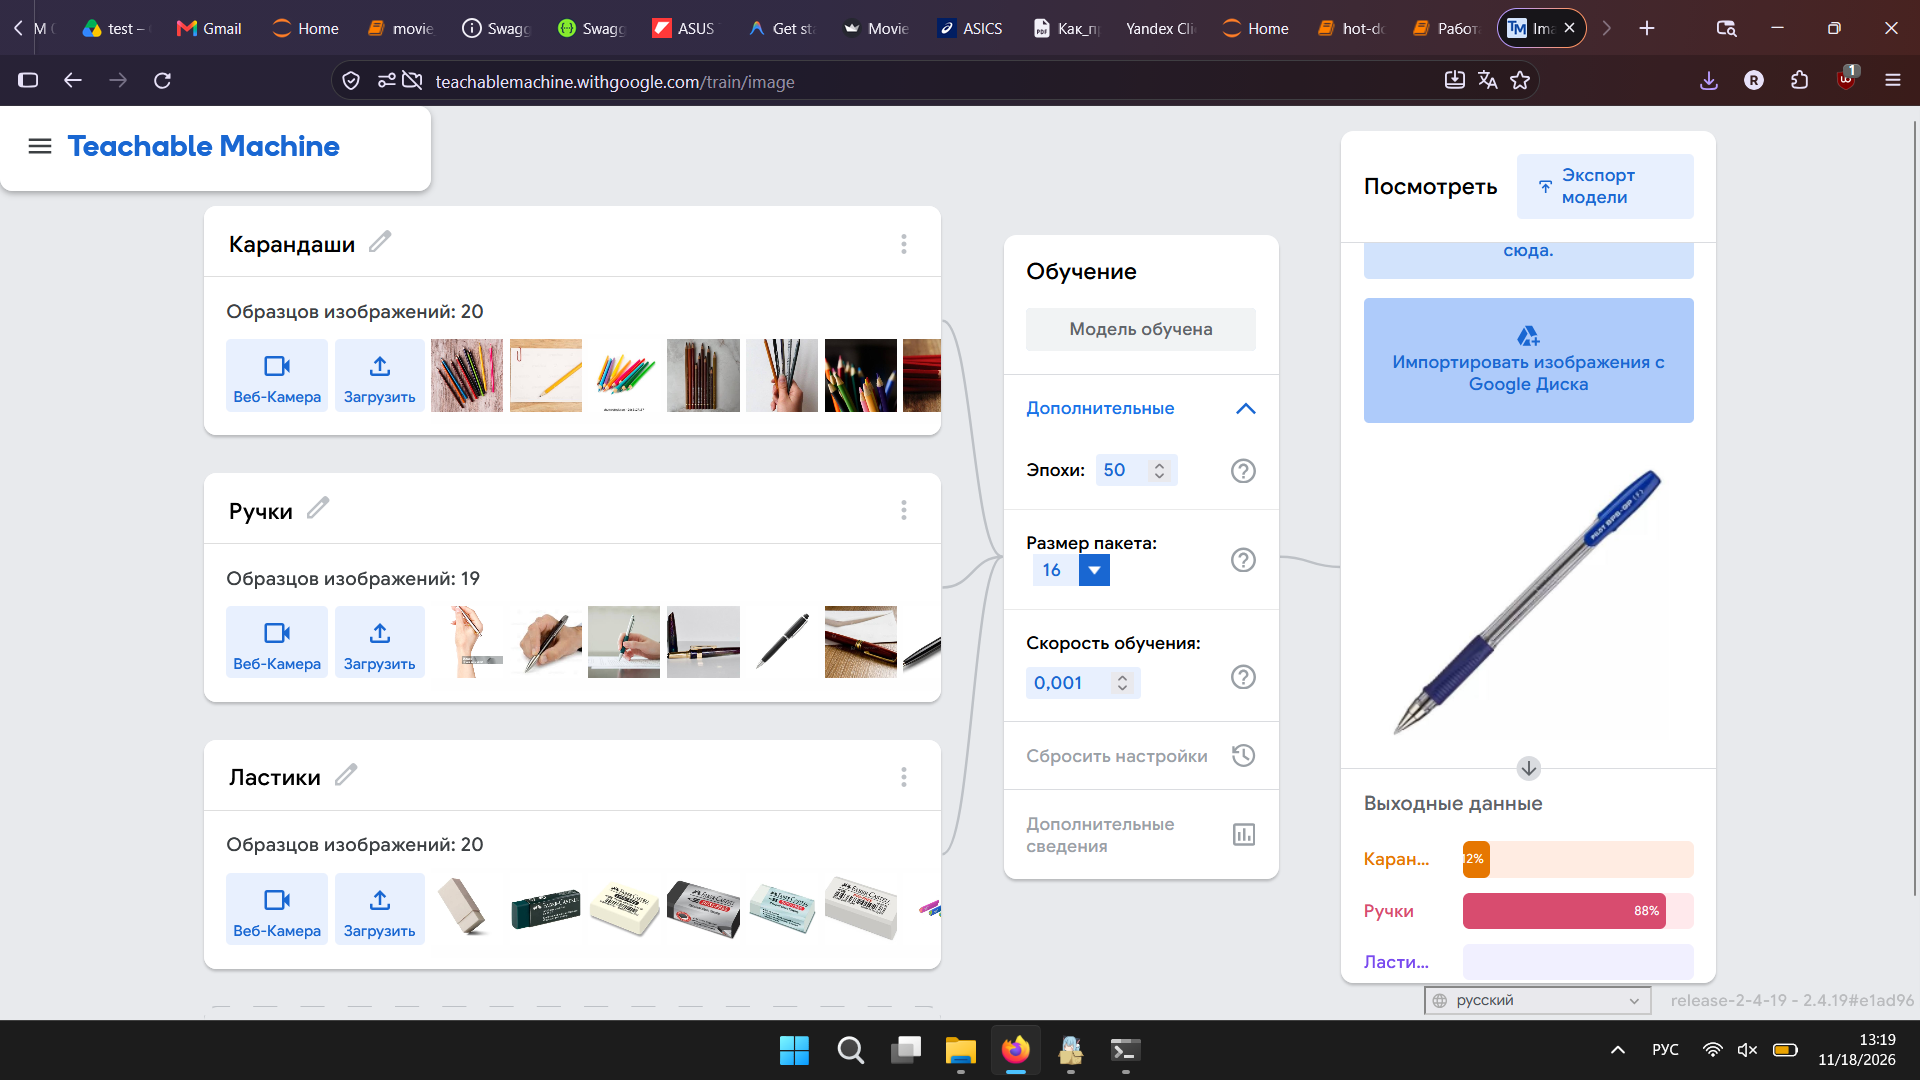

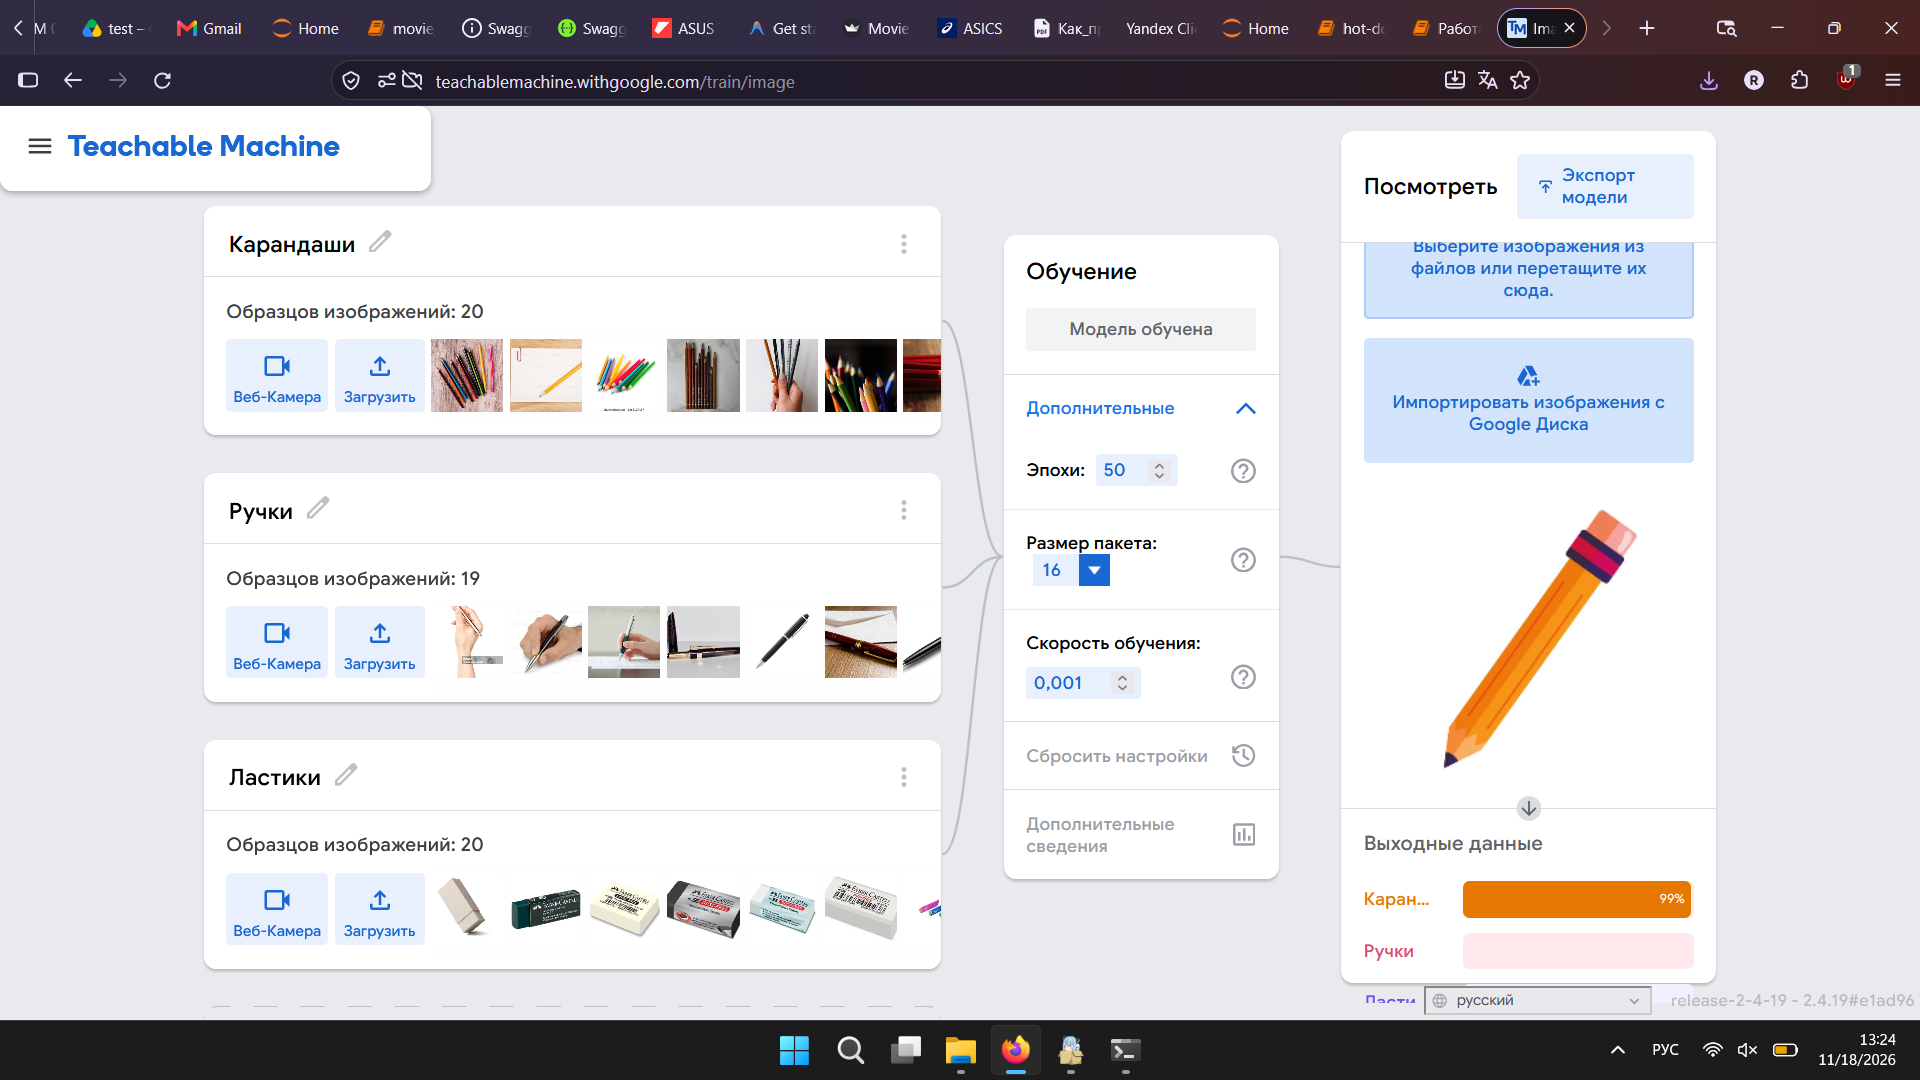

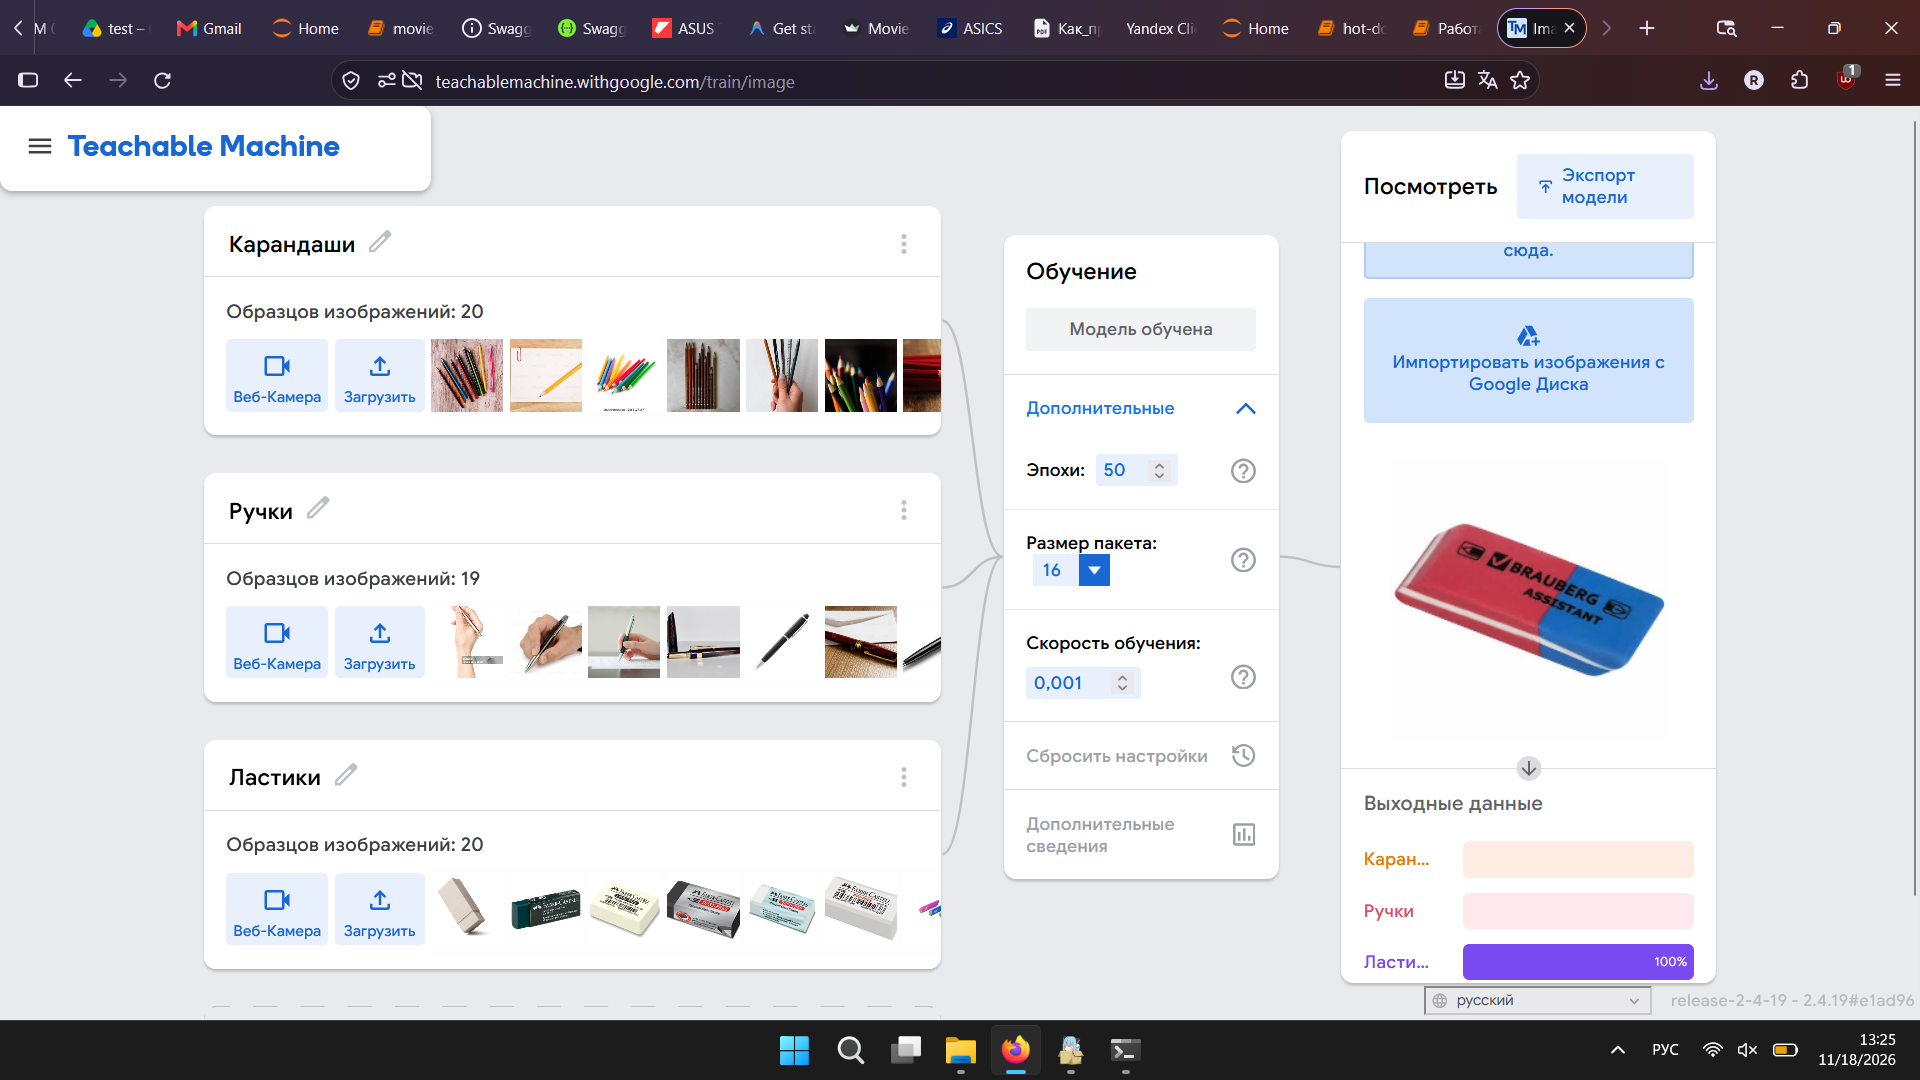

3. Проверка на неизвестных изображениях
Модель была протестирована на новых изображениях, не участвовавших в обучении:   Новое фото шариковой ручки — класс «Ручки» (уверенность 98%, «Карандаши» — 2%).   Изображение карандаша — класс «Карандаши» (уверенность 99%).   Фото красно-синего ластика Brauberg — класс «Ластики» (уверенность 100%). 

4. Проверка модели в Jupyter Notebook
Модель сохранена локально (keras_Model.h5(1) и labels(1).txt) и протестирована через скрипт на Python с использованием tf_keras.




1/1 [==============================] - 2s 2s/step
------------------------------
Файл: images.jpg
Класс: Карандаши
Уверенность: 0.9916
------------------------------


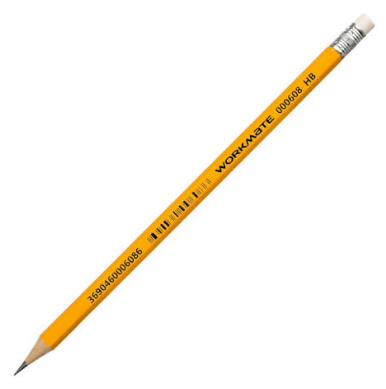

In [1]:
import os
import tf_keras 
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True)

model_path = "keras_Model.h5(1)"
labels_path = "labels(1).txt"

if not os.path.exists(model_path):
    raise FileNotFoundError(f"Файл модели '{model_path}' не найден! Проверь, нет ли пробела перед (1) или расширения в конце.")
if not os.path.exists(labels_path):
    raise FileNotFoundError(f"Файл лейблов '{labels_path}' не найден! Проверь точное название.")

model = tf_keras.models.load_model(model_path, compile=False)

with open(labels_path, "r", encoding="utf-8") as f:
    class_names = f.readlines()

image_folder = "C:/Users/rafael/Desktop/Задание 2/карандаши"
image_filename = "images.jpg" 

image_path = os.path.join(image_folder, image_filename)

if not os.path.exists(image_path):
    raise FileNotFoundError(f"Картинка '{image_path}' не найдена! Проверь путь и имя.")

data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

image = Image.open(image_path).convert("RGB")
size = (224, 224)
image_resized = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image_resized)

normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index].strip()
confidence_score = prediction[0][index]

print("-" * 30)
print(f"Файл: {image_filename}")
print(f"Класс: {class_name[2:]}") 
print(f"Уверенность: {confidence_score:.4f}")
print("-" * 30)

plt.imshow(image)
plt.axis('off')
plt.show()

Результат запуска:Файл: images.jpg (из папки «карандаши»).   Предсказанный класс: Карандаши.   Уверенность: 0.9916 (99,16%).

Вывод по заданию 2: несмотря на небольшой объем датасета (около 20 фото на класс), модель за счет переноса обучения (transfer learning) в Teachable Machine уверенно распознает новые изображения канцелярии на чистом фоне с точностью 98–100%. Для повышения устойчивости на сложных фонах и устранения путаницы между ручками и другими предметами необходимо расширить выборку фотографиями под разными углами и освещением.

Задание 3. Обучение модели на смартфоне в приложении Pocket AutoML

1. Создание проекта и сбор данных
На смартфон было установлено приложение Pocket AutoML, позволяющее обучать модели глубокого обучения локально на устройстве. В приложении создана задача «крутые предметы» с тремя классами объектов мебели:   Парты;   Скамейки;   Стулья. 

На вкладке «Данные» в каждый класс было загружено не менее 10 изображений, после чего на вкладке «Модель» выполнена первичная тренировка.

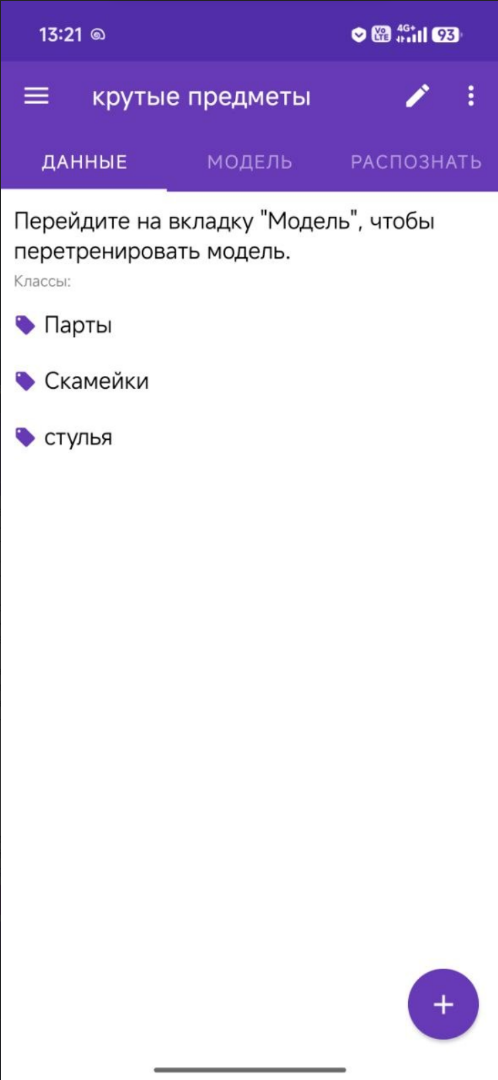

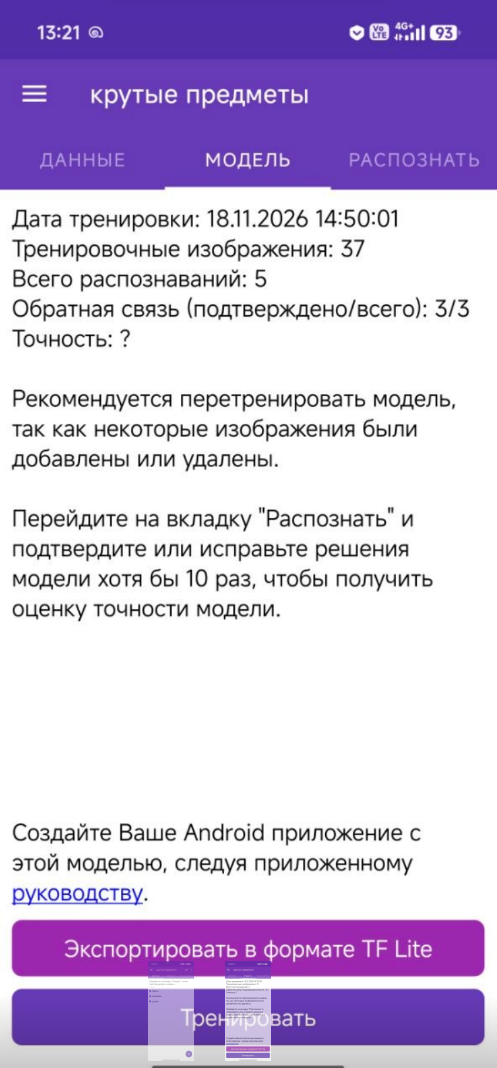

2. Тестирование и дообучение с обратной связью
На вкладке «Распознать» модель была проверена на новых изображениях. С помощью кнопок «Подтвердить» и «Исправить» новые примеры добавлялись в соответствующие классы, после чего была проведена повторная тренировка модели.

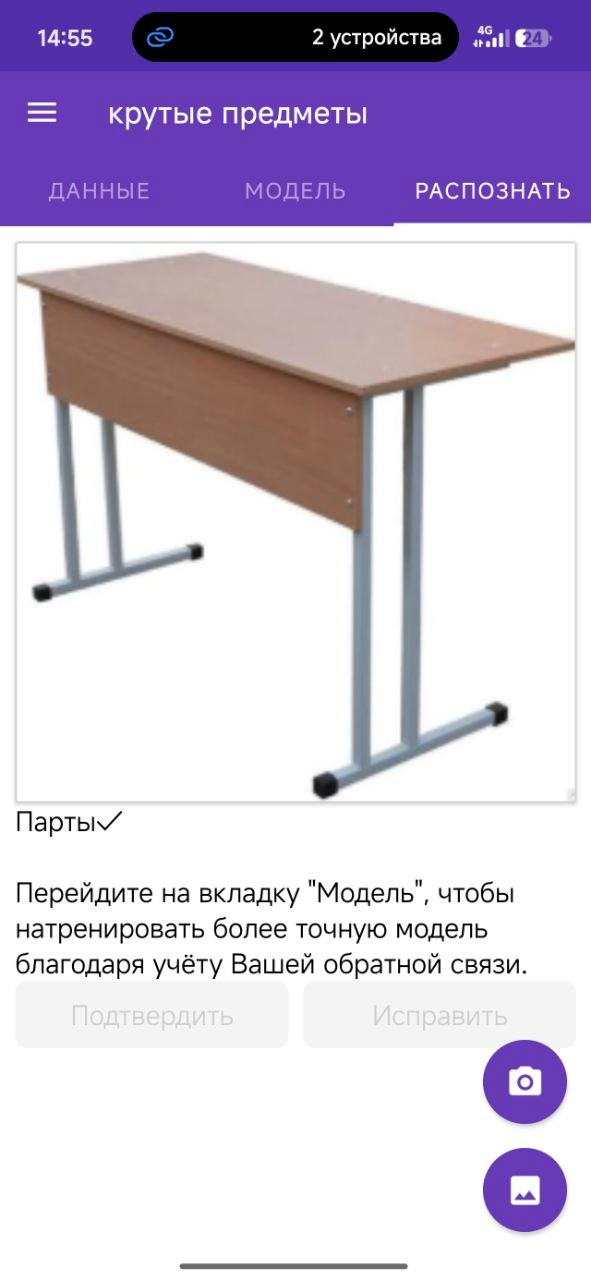

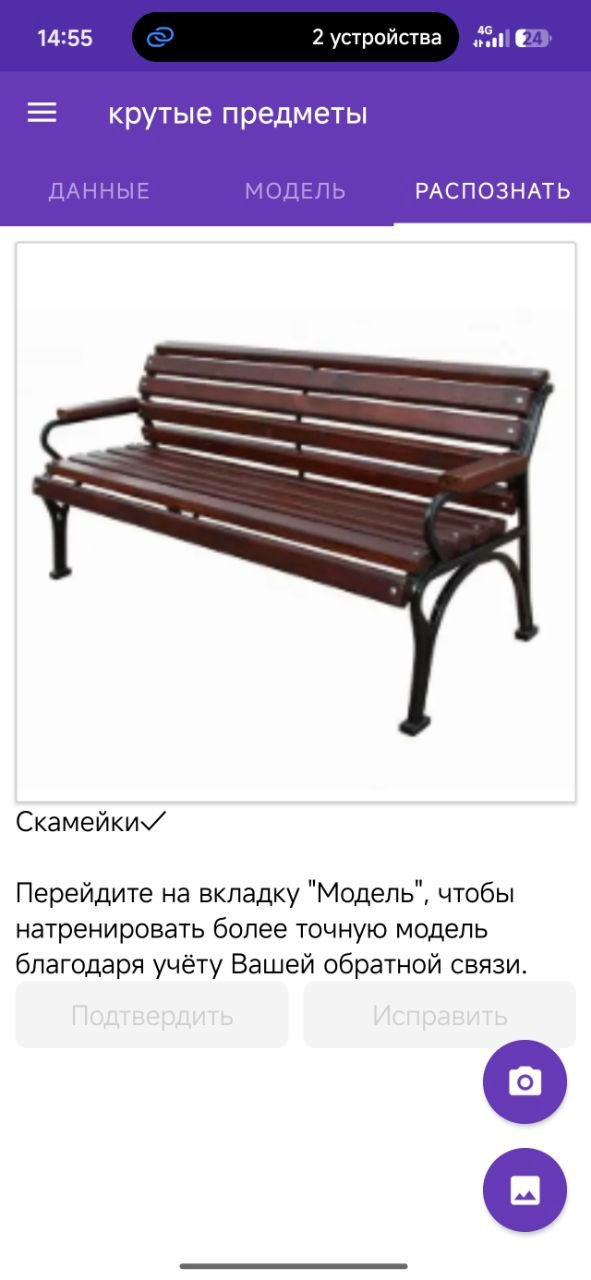

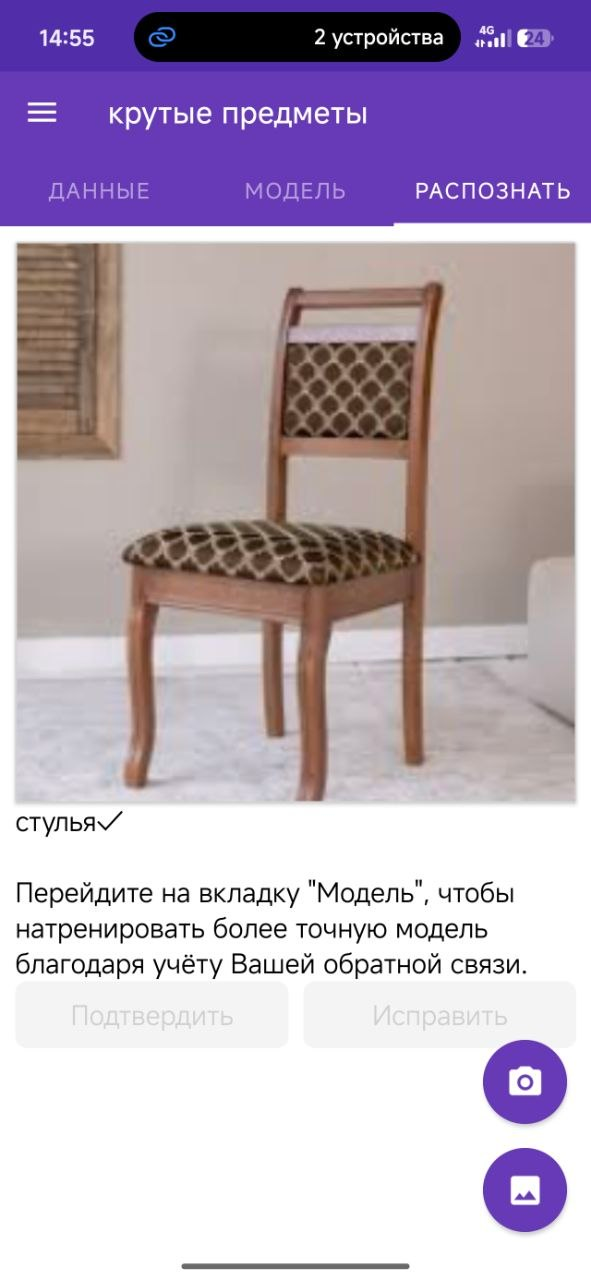

Вывод о качестве распознавания и причинах ошибок:
Модель корректно распознает четкие одиночные объекты на нейтральном фоне (скамейка, стул, парта). Повторное обучение после подтверждения и исправления примеров заметно снижает количество ошибок.

Основные причины, по которым модель в Pocket AutoML может ошибаться:   Схожесть объектов: парты, скамейки и стулья имеют общие визуальные признаки — деревянные поверхности, металлические ножки, прямые углы и схожие цвета.Малый размер датасета: при 10–20 фото на класс модель запоминает не только сам объект, но и фон (пол, стены, белую подложку), поэтому смена фона сбивает классификатор.Ракурс и освещение: если объект снят слишком близко, частично перекрыт другими предметами или находится в тени, признаки искажаются.

Задание 4. Разработка API и графического приложения

Для практического применения обученной нейросети из Задания 2 (распознавание канцелярии: карандаши, ручки, ластики) разработана клиент-серверная система на Python в среде PyCharm, разделенная на бэкенд и фронтенд.

1. Программный интерфейс (API) — main.pyСерверная часть реализована на фреймворке FastAPI с запуском через ASGI-сервер Uvicorn.При запуске сервера модель (keras_Model.h5) и файл меток (labels.txt) загружаются в память однократно через tf_keras, чтобы не тратить время на чтение диска при каждом запросе.Реализован эндпоинт POST /predict, принимающий загруженный файл изображения (UploadFile).Изображение конвертируется в RGB, приводится к размеру $224 \times 224$ методом ImageOps.fit и нормализуется.После выполнения model.predict() API возвращает JSON-ответ с названием распознанного класса и значением точности (уверенности) в формате float

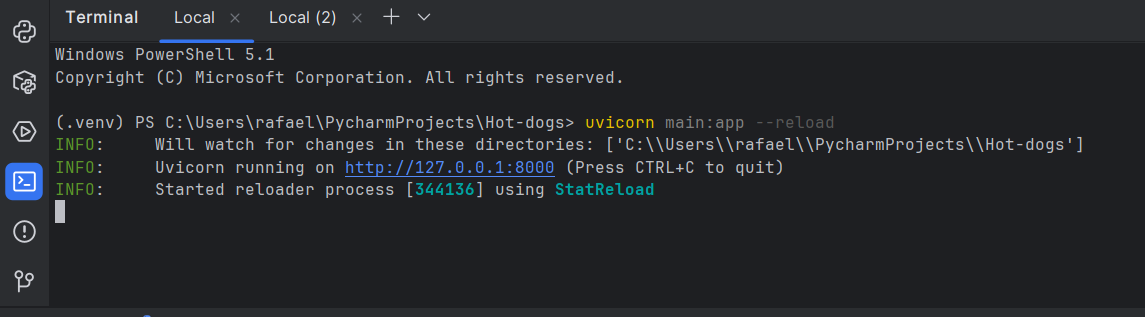

2. Приложение с графическим интерфейсом — app_streamlit.py
Клиентская часть разработана на библиотеке Streamlit. Интерфейс позволяет пользователю:

    Загрузить изображение в формате .jpg, .jpeg или .png через виджет st.file_uploader.

    Увидеть предпросмотр загруженной фотографии прямо на странице.

    По нажатию кнопки «Распознать» отправить POST-запрос с файлом на локальный API ([http://127.0.0.1:8000/predict](http://127.0.0.1:8000/predict)) с помощью библиотеки requests.

    Получить JSON-ответ от сервера и вывести на экран определенный класс предмета и степень уверенности модели. Также предусмотрена обработка ошибки соединения, если сервер API не запущен.

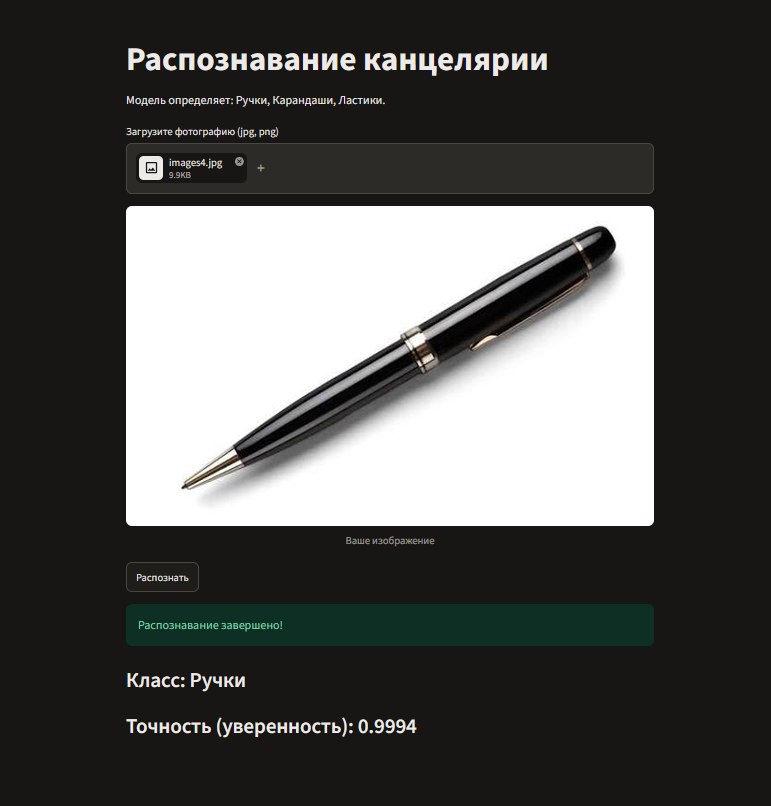

В результате выполнения работы были освоены инструменты быстрого прототипирования моделей компьютерного зрения (Teachable Machine и Pocket AutoML), решены технические проблемы совместимости версий TensorFlow/Keras при локальном запуске моделей, а также собран полноценный прототип приложения с разделением на REST API (FastAPI) и пользовательский веб-интерфейс (Streamlit).